#**Import Libraries**

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')

# Scikit-learn imports
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Lasso, Ridge

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully!")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Libraries imported successfully!


In [1]:

import pandas as pd
import numpy as np

# Load dataset
file_path = "/content/drive/MyDrive/Hamza - AI ML-Learning/Task_day_20/data.csv"

df = pd.read_csv(file_path)

# Display first 5 rows
display(df.head())

# Dataset shape
print("Dataset Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Data types
print("\nData Types:")
print(df.dtypes)

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Statistical summary
display(df.describe(include="all"))


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


Dataset Shape: (4600, 18)

Columns:
['date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'street', 'city', 'statezip', 'country']

Data Types:
date              object
price            float64
bedrooms         float64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
street            object
city              object
statezip          object
country           object
dtype: object

Missing Values:
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renov

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
count,4600,4.600000e+03,4600.000000,4600.000000,4600.000000,4.600000e+03,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600,4600,4600,4600
unique,70,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4525,44,77,1
top,2014-06-23 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2520 Mulberry Walk NE,Seattle,WA 98103,USA
freq,142,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,1573,148,4600
mean,NaN,5.519630e+05,3.400870,2.160815,2139.346957,1.485252e+04,1.512065,0.007174,0.240652,3.451739,1827.265435,312.081522,1970.786304,808.608261,NaN,NaN,NaN,NaN
std,NaN,5.638347e+05,0.908848,0.783781,963.206916,3.588444e+04,0.538288,0.084404,0.778405,0.677230,862.168977,464.137228,29.731848,979.414536,NaN,NaN,NaN,NaN
min,NaN,0.000000e+00,0.000000,0.000000,370.000000,6.380000e+02,1.000000,0.000000,0.000000,1.000000,370.000000,0.000000,1900.000000,0.000000,NaN,NaN,NaN,NaN
25%,NaN,3.228750e+05,3.000000,1.750000,1460.000000,5.000750e+03,1.000000,0.000000,0.000000,3.000000,1190.000000,0.000000,1951.000000,0.000000,NaN,NaN,NaN,NaN
50%,NaN,4.609435e+05,3.000000,2.250000,1980.000000,7.683000e+03,1.500000,0.000000,0.000000,3.000000,1590.000000,0.000000,1976.000000,0.000000,NaN,NaN,NaN,NaN
75%,NaN,6.549625e+05,4.000000,2.500000,2620.000000,1.100125e+04,2.000000,0.000000,0.000000,4.000000,2300.000000,610.000000,1997.000000,1999.000000,NaN,NaN,NaN,NaN


In [2]:

# Target variable
y = df["price"]

# Selected input features
features = [
    "bedrooms",
    "bathrooms",
    "sqft_living",
    "sqft_lot",
    "floors",
    "waterfront",
    "view",
    "condition",
    "yr_built",
    "yr_renovated"
]

X = df[features]

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

display(X.head())
display(y.head())


Input Features Shape: (4600, 10)
Target Shape: (4600,)


,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,yr_built,yr_renovated
0,3.0,1.50,1340,7912,1.5,0,0,3,1955,2005
1,5.0,2.50,3650,9050,2.0,0,4,5,1921,0
2,3.0,2.00,1930,11947,1.0,0,0,4,1966,0
3,3.0,2.25,2000,8030,1.0,0,0,4,1963,0
4,4.0,2.50,1940,10500,1.0,0,0,4,1976,1992


,price
0,313000.0
1,2384000.0
2,342000.0
3,420000.0
4,550000.0


#**Split training and testing data**

In [4]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Features: (3680, 10)
Testing Features: (920, 10)
Training Target: (3680,)
Testing Target: (920,)


#**Preprocess the data**

In [5]:

preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("Preprocessing pipeline created!")


Preprocessing pipeline created!


#**Train 3 Models**

In [6]:

models = {
    "Linear Regression (Baseline)": LinearRegression(),

    "L1 - Lasso": Lasso(alpha=1.0, max_iter=20000),

    "L2 - Ridge": Ridge(alpha=1.0)
}

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(f"{name} trained successfully!")



Linear Regression (Baseline) trained successfully!
L1 - Lasso trained successfully!
L2 - Ridge trained successfully!


#**Evaluate the Performance**

In [7]:

results = []

for name, model in trained_models.items():

    # Predictions
    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    # Training metrics
    train_r2 = r2_score(y_train, train_predictions)

    # Testing metrics
    test_r2 = r2_score(y_test, test_predictions)

    mae = mean_absolute_error(y_test, test_predictions)

    mse = mean_squared_error(y_test, test_predictions)

    rmse = np.sqrt(mse)

    results.append({
        "Model": name,
        "Train R2": train_r2,
        "Test R2": test_r2,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))


,Model,Train R2,Test R2,MAE,MSE,RMSE
0,Linear Regression (Baseline),0.5441,0.0321,210935.0641,9.871304e+11,993544.3504
1,L1 - Lasso,0.5441,0.0321,210934.6988,9.871300e+11,993544.1761
2,L2 - Ridge,0.5441,0.0321,210918.5375,9.871089e+11,993533.5450


#**Compare L1 L2**

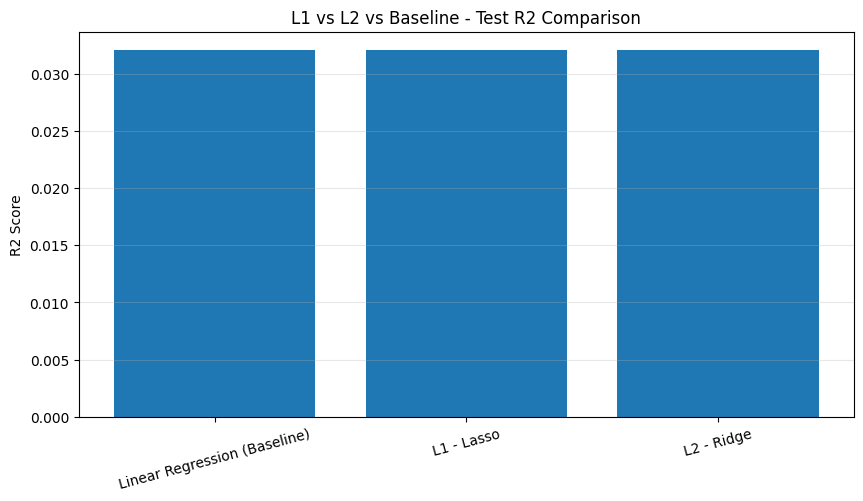

In [8]:

plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["Test R2"]
)

plt.title("L1 vs L2 vs Baseline - Test R2 Comparison")
plt.ylabel("R2 Score")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

plt.show()


#**Compare feature coefficients**

In [9]:

coefficients = pd.DataFrame({
    "Feature": features
})

for name, pipeline in trained_models.items():

    model_coefficients = pipeline.named_steps["model"].coef_

    coefficients[name] = model_coefficients

display(coefficients.round(4))


,Feature,Linear Regression (Baseline),L1 - Lasso,L2 - Ridge
0,bedrooms,-58807.4495,-58804.4700,-58718.0753
1,bathrooms,27778.0845,27776.3860,27866.6900
2,sqft_living,269752.2025,269750.3792,269537.0185
3,sqft_lot,-18022.2316,-18021.0126,-17995.2746
4,floors,39186.3178,39184.8079,39174.7801
5,waterfront,32664.7496,32664.1824,32665.5958
6,view,34095.6194,34095.6096,34124.5882
7,condition,19600.2089,19598.6545,19599.9738
8,yr_built,-75914.9585,-75913.5429,-75876.8501
9,yr_renovated,8068.7114,8067.1600,8075.2831


#**Check overfitting and underfitting**

In [10]:

comparison = results_df[["Model", "Train R2", "Test R2"]].copy()

comparison["Train-Test Gap"] = (
    comparison["Train R2"] - comparison["Test R2"]
)

display(comparison.round(4))


,Model,Train R2,Test R2,Train-Test Gap
0,Linear Regression (Baseline),0.5441,0.0321,0.5121
1,L1 - Lasso,0.5441,0.0321,0.5121
2,L2 - Ridge,0.5441,0.0321,0.5120


#**Test your model with a new house**

In [11]:

new_house = pd.DataFrame([{
    "bedrooms": 3,
    "bathrooms": 2,
    "sqft_living": 1800,
    "sqft_lot": 5000,
    "floors": 1,
    "waterfront": 0,
    "view": 0,
    "condition": 3,
    "yr_built": 2005,
    "yr_renovated": 0
}])

for name, model in trained_models.items():

    prediction = model.predict(new_house)[0]

    print(f"{name}: ${prediction:,.2f}")


Linear Regression (Baseline): $316,237.28
L1 - Lasso: $316,242.10
L2 - Ridge: $316,290.37
